# Orvians Technologies - Week 2 EDA Notebook

**Project:** Invoice Payment Delay & Cash-Flow Intelligence Platform  
**Dataset:** Week 1 cleaned Customer Invoices Dataset  
**Main output:** Statistical EDA, at least 12 labelled charts, customer analysis, overview KPIs, aging and ML hypotheses.

## How to run
1. Extract the submission folder.
2. Install dependencies: `pip install -r requirements.txt`.
3. Open this notebook from the submission root folder (the folder containing `data/`, `src/` and `outputs/`).
4. Run all cells from top to bottom. The analysis pipeline writes charts and summary CSV/JSON files into `outputs/`.

The notebook calls the included `src/eda_pipeline.py`, so all EDA transformations and charts are reusable from Python as well as from this notebook.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data' / 'cleaned_invoices.csv').exists():
    raise FileNotFoundError('Open this notebook from the extracted Week 2 submission folder. Expected data/cleaned_invoices.csv.')
DATA_PATH = ROOT / 'data' / 'cleaned_invoices.csv'
OUTPUT_PATH = ROOT / 'outputs'
sys.path.insert(0, str(ROOT / 'src'))
from eda_pipeline import run
print('Data:', DATA_PATH)
print('Output folder:', OUTPUT_PATH)

Data: /mnt/data/Orvians_Week2_EDA_Submission/data/cleaned_invoices.csv
Output folder: /mnt/data/Orvians_Week2_EDA_Submission/outputs


## 1. Load and inspect the cleaned dataset

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print('Shape:', df.shape)
display(df.head())
profile = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'missing': df.isna().sum(),
    'unique': df.nunique(dropna=True)
})
display(profile)

Shape: (48839, 35)


,business_code,cust_number,name_customer,clear_date,buisness_year,doc_id,posting_date,document_create_date,document_create_date.1,due_in_date,invoice_currency,document type,posting_id,total_open_amount,baseline_create_date,cust_payment_terms,invoice_id,isOpen,quality_flag_due_before_invoice_date,quality_flag_negative_amount,quality_flag_amount_iqr_outlier,invoice_date,due_date,payment_date,customer_id,customer_name,amount,currency,country,invoice_status,days_to_pay,delay,paid_late_flag,quality_flag_payment_before_invoice_date,quality_flag_status_payment_date_mismatch
0,U001,0200769623,WAL-MAR CORP,2020-02-11,2020,1930438491,2020-01-26,2020-01-25,2020-01-26,2020-02-10,USD,RV,1,54273.28,2020-01-26,NAH4,1930438491,0,False,False,False,2020-01-26,2020-02-10,2020-02-11,0200769623,WAL-MAR CORP,54273.28,USD,NaN,paid,16.0,1.0,True,False,False
1,U001,0200980828,BEN E,2019-08-08,2019,1929646410,2019-07-22,2019-07-22,2019-07-22,2019-08-11,USD,RV,1,79656.60,2019-07-22,NAD1,1929646410,0,False,False,False,2019-07-22,2019-08-11,2019-08-08,0200980828,BEN E,79656.60,USD,NaN,paid,17.0,-3.0,False,False,False
2,U001,0200792734,MDV/ TRUST,2019-12-30,2019,1929873765,2019-09-14,2019-09-14,2019-09-14,2019-09-29,USD,RV,1,2253.86,2019-09-14,NAA8,1929873765,0,False,False,False,2019-09-14,2019-09-29,2019-12-30,0200792734,MDV/ TRUST,2253.86,USD,NaN,paid,107.0,92.0,True,False,False
3,CA02,0140105686,SYSC LLC,NaN,2020,2960623488,2020-03-30,2020-03-30,2020-03-30,2020-04-10,CAD,RV,1,3299.70,2020-03-31,CA10,2960623488,1,False,False,False,2020-03-31,2020-04-10,NaN,0140105686,SYSC LLC,3299.70,CAD,NaN,open,NaN,NaN,NaN,False,False
4,U001,0200769623,WAL-MAR FOUNDATION,2019-11-25,2019,1930147974,2019-11-13,2019-11-13,2019-11-13,2019-11-28,USD,RV,1,33133.29,2019-11-13,NAH4,1930147974,0,False,False,False,2019-11-13,2019-11-28,2019-11-25,0200769623,WAL-MAR FOUNDATION,33133.29,USD,NaN,paid,12.0,-3.0,False,False,False


,dtype,non_null,missing,unique
business_code,object,48839,0,6
cust_number,object,48839,0,1425
name_customer,object,48839,0,4132
clear_date,object,39158,9681,403
buisness_year,int64,48839,0,2
doc_id,int64,48839,0,48839
posting_date,object,48839,0,506
document_create_date,object,48839,0,507
document_create_date.1,object,48839,0,506
due_in_date,object,48839,0,547


## 2. Run the reusable EDA pipeline

In [3]:
analysis_df, paid_df, open_df, metrics = run(DATA_PATH, OUTPUT_PATH)
print(json.dumps(metrics, indent=2))

{
  "total_invoices": 48839,
  "paid_invoices": 39158,
  "open_invoices": 9681,
  "paid_late": 16418,
  "paid_on_time": 8271,
  "paid_early": 14469,
  "paid_late_rate": 0.41927575463506817,
  "median_days_to_pay": 15.0,
  "mean_days_to_pay": 18.078017263394454,
  "median_payment_delay": 0.0,
  "mean_payment_delay": 0.8371469431533787,
  "open_overdue_invoices": 9181,
  "open_not_yet_due_invoices": 394,
  "open_due_on_cutoff_invoices": 106,
  "aging_cutoff_proxy": "2020-05-22",
  "currency_open_amount": {
    "CAD": 42218190.72,
    "USD": 280875125.47
  },
  "country_analysis_available": false,
  "customer_ids_paid": 1344,
  "customer_ids_with_20plus_paid": 219,
  "amount_outlier_flagged": 2460,
  "customer_name_unique_count": 4132,
  "customer_id_unique_count": 1425
}


## 3. Overview metrics and aging summary

In [4]:
display(pd.Series(metrics, name='value').to_frame())
aging_table = pd.read_csv(OUTPUT_PATH / 'aging_summary.csv')
display(aging_table)
print('Aging cut-off is a proxy derived from the latest date in the data:', metrics['aging_cutoff_proxy'])

,value
total_invoices,48839
paid_invoices,39158
open_invoices,9681
paid_late,16418
paid_on_time,8271
paid_early,14469
paid_late_rate,0.419276
median_days_to_pay,15.0
mean_days_to_pay,18.078017
median_payment_delay,0.0


,aging_bucket,invoice_count,outstanding_amount
0,Not yet due,394,7.191002e+06
1,0-30 days,3673,1.222681e+08
2,31-60 days,4427,1.556094e+08
3,61-90 days,1187,3.802483e+07
4,91+ days,0,0.000000e+00


Aging cut-off is a proxy derived from the latest date in the data: 2020-05-22


## 4. Chart gallery - 16 labelled charts

All charts are generated by the reusable script. Payment-delay charts use paid invoices only. Amount comparisons are separated by currency. The monthly paid-delay trend excludes months with fewer than 100 paid invoices because recent records are mostly open.

### Chart01 Amount Distribution

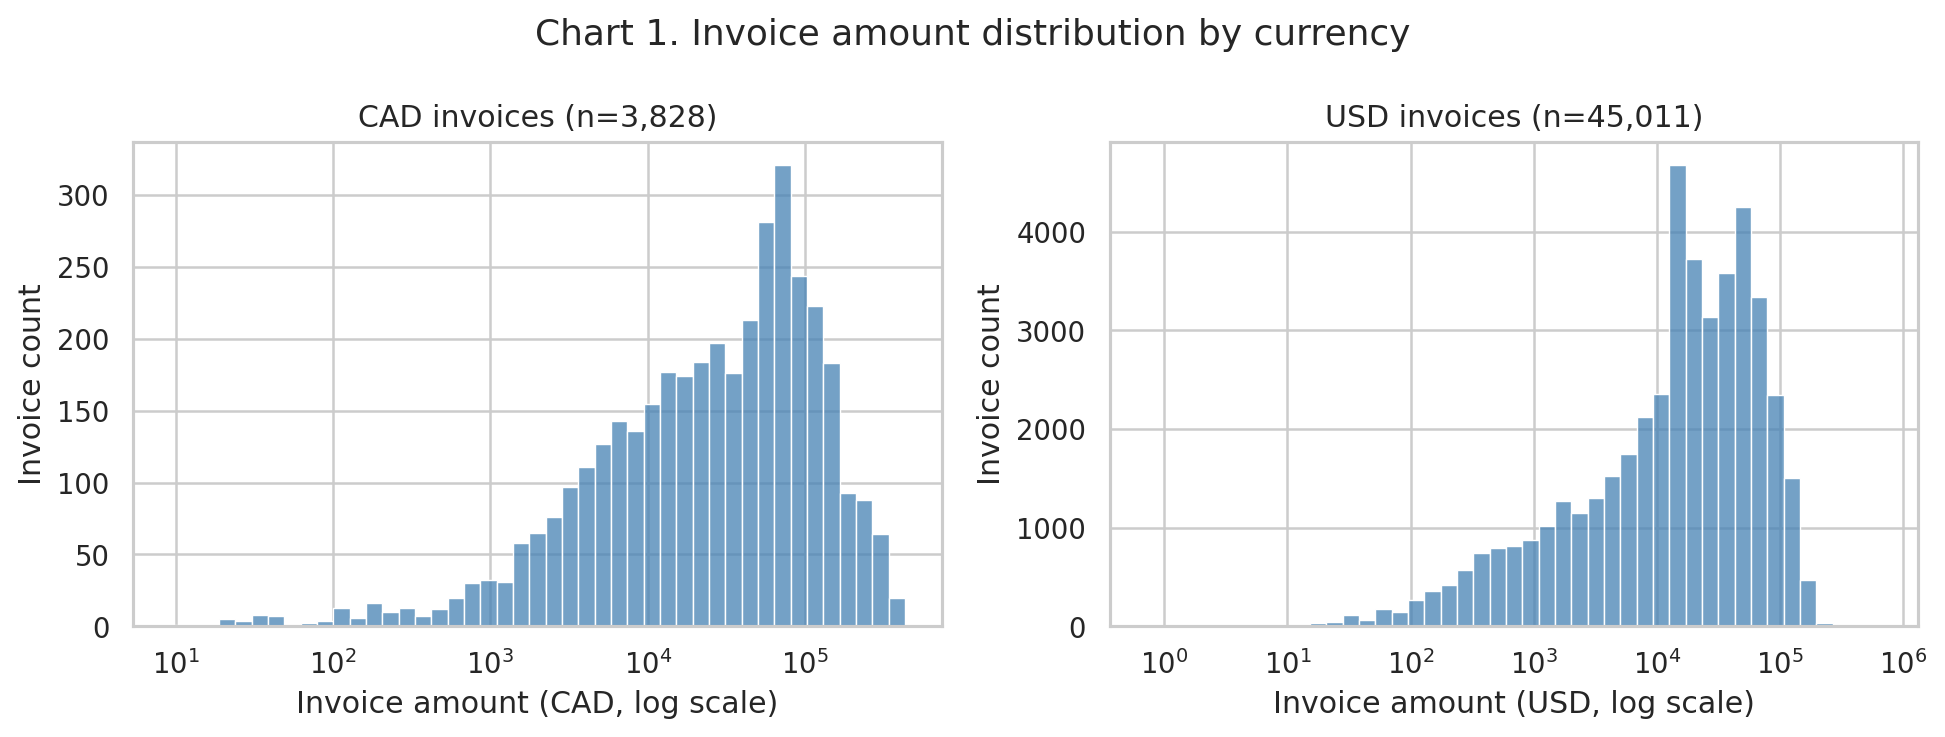

In [5]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart01_amount_distribution.png')))

### Chart02 Amount Boxplot

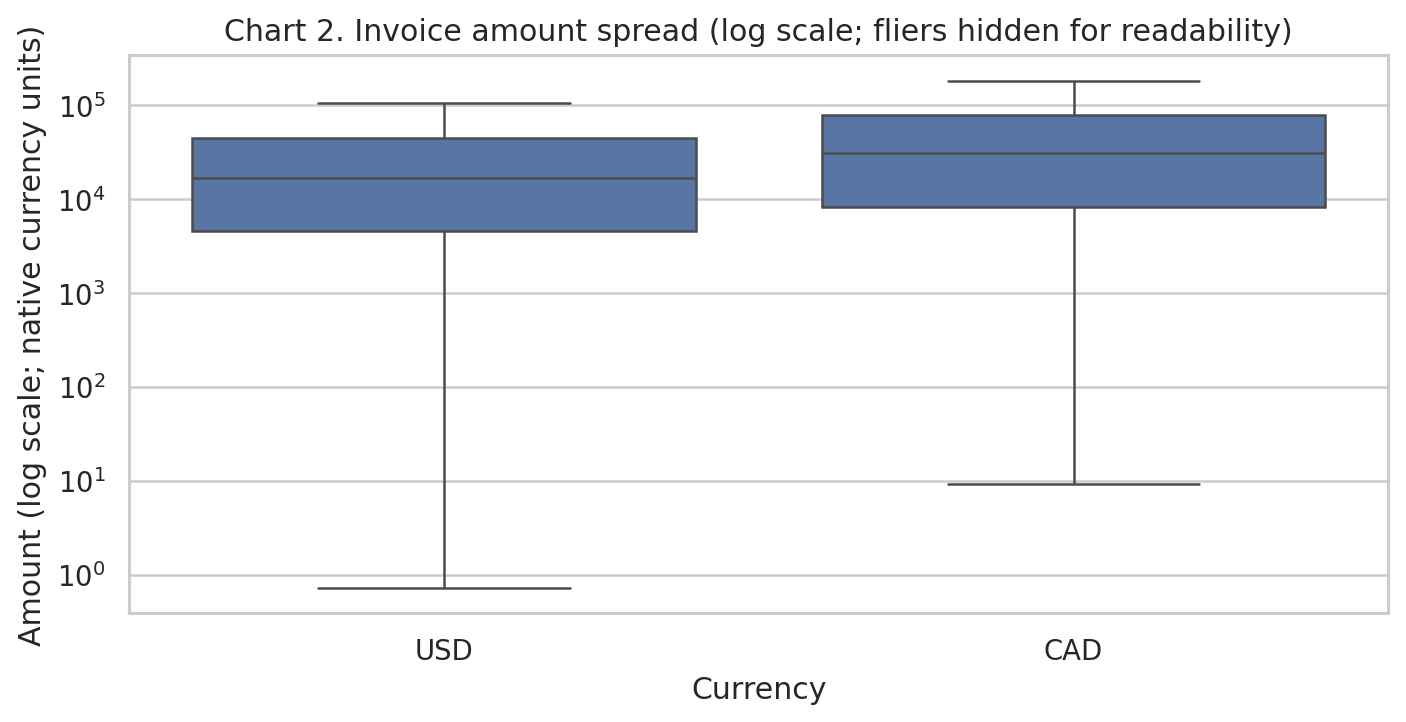

In [6]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart02_amount_boxplot.png')))

### Chart03 Days To Pay

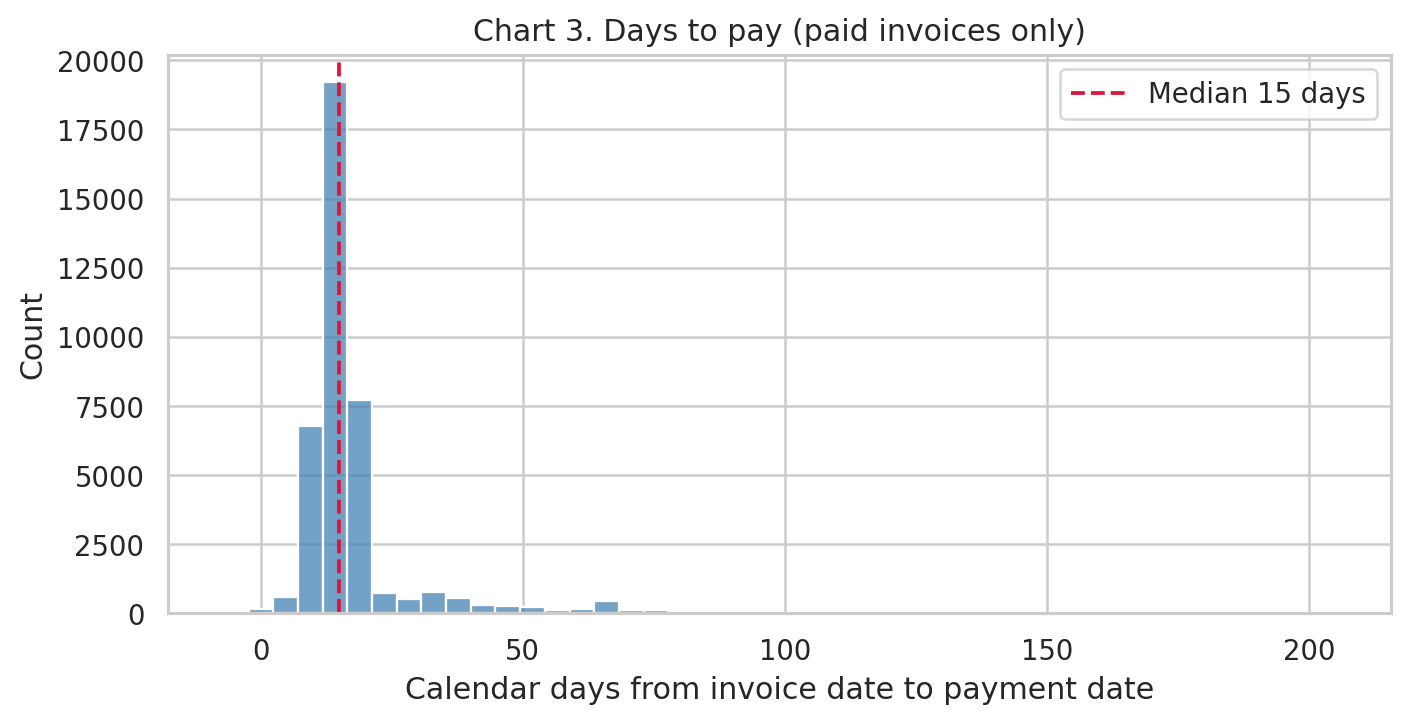

In [7]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart03_days_to_pay.png')))

### Chart04 Payment Delay

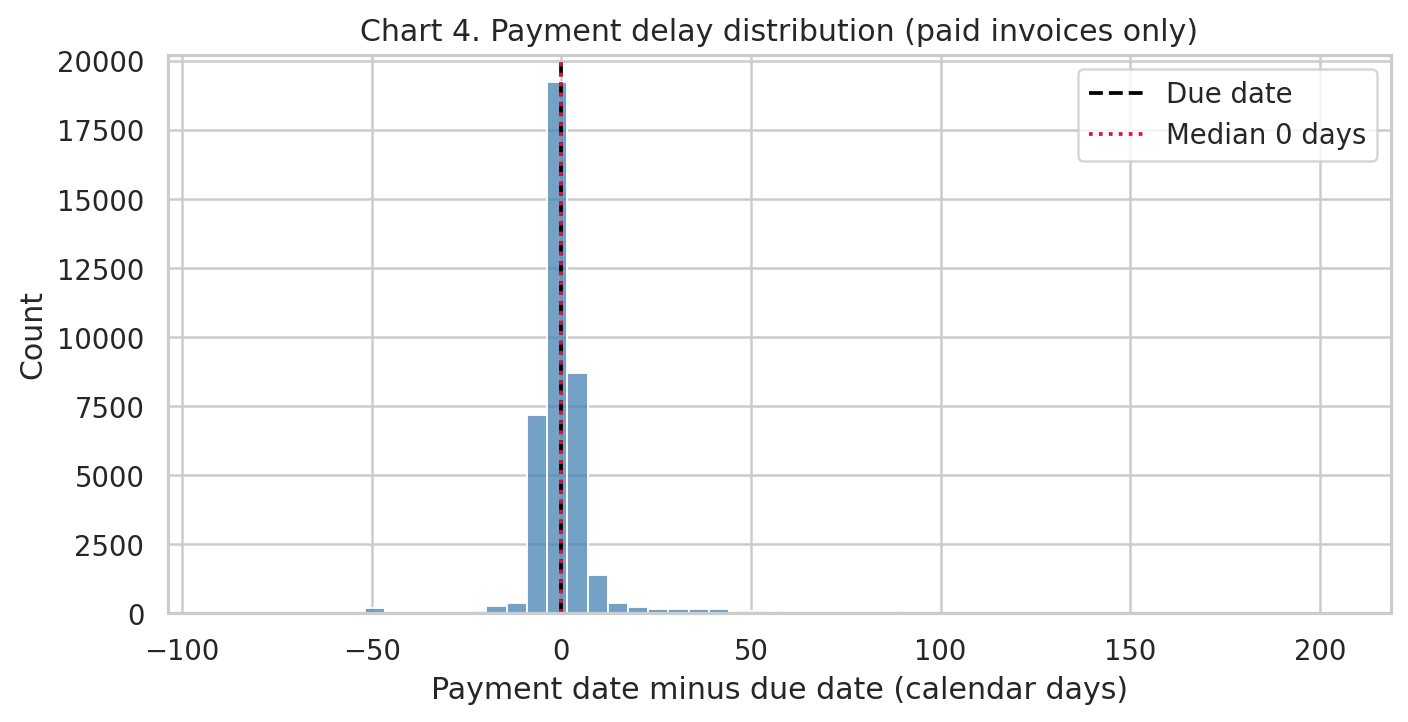

In [8]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart04_payment_delay.png')))

### Chart05 Payment Outcomes

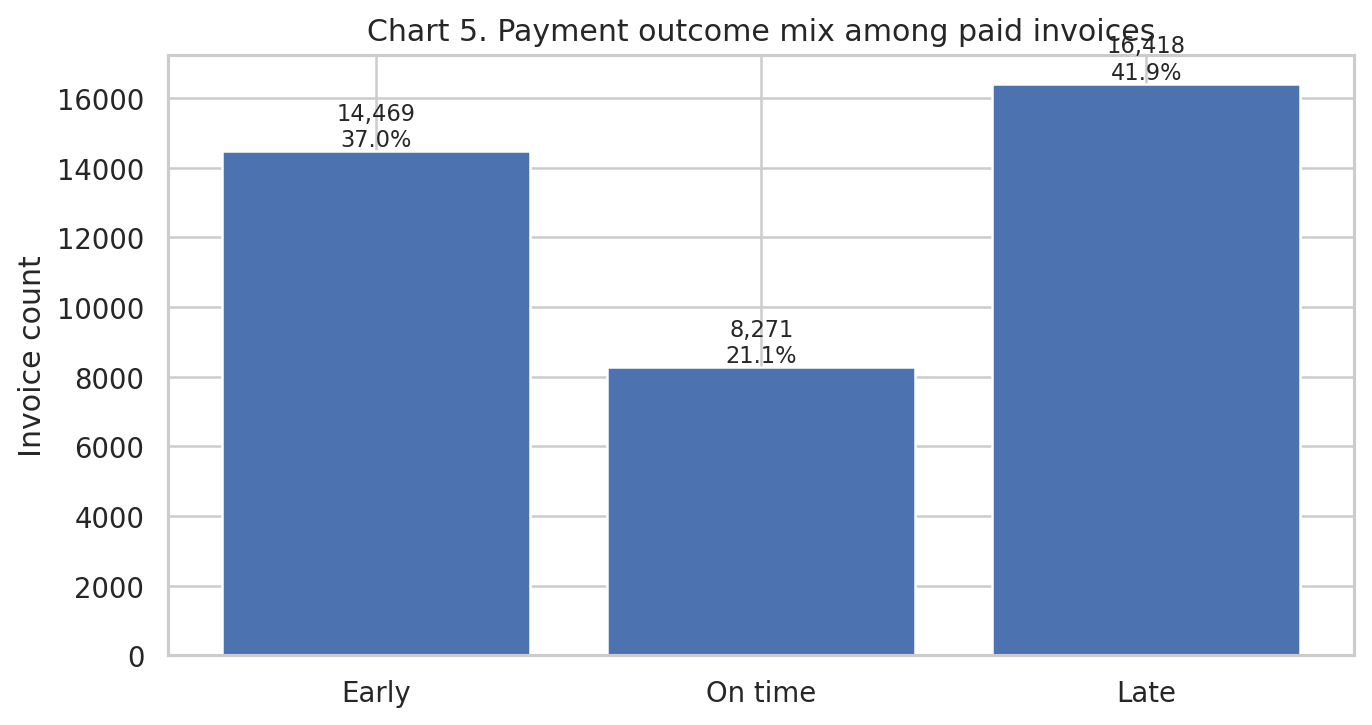

In [9]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart05_payment_outcomes.png')))

### Chart06 Amount Vs Delay

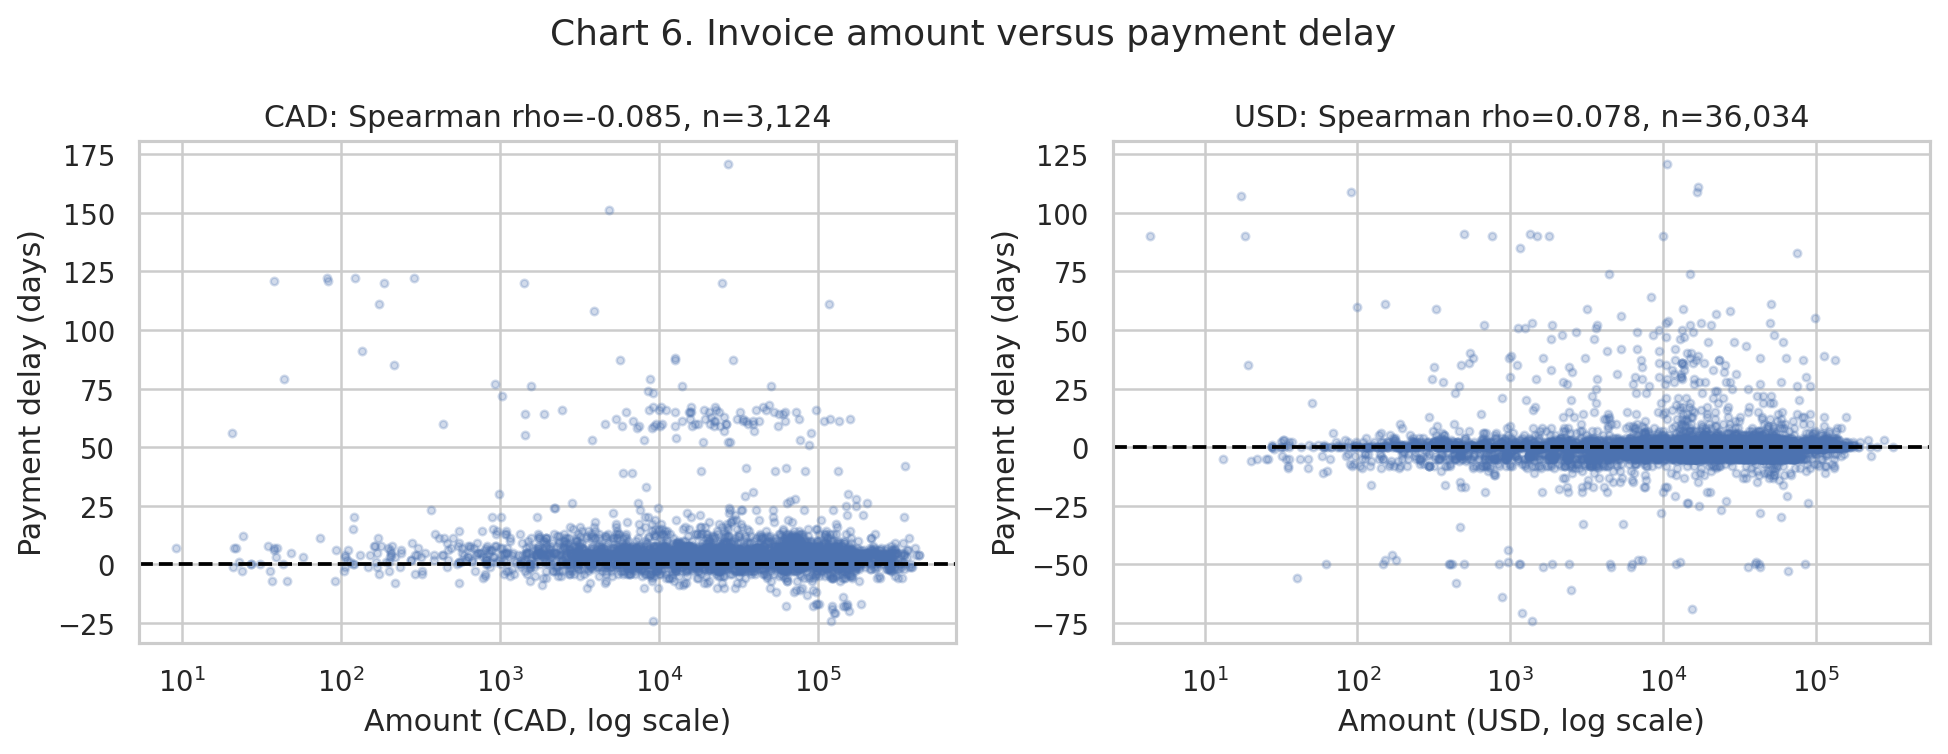

In [10]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart06_amount_vs_delay.png')))

### Chart07 Terms Late Rate

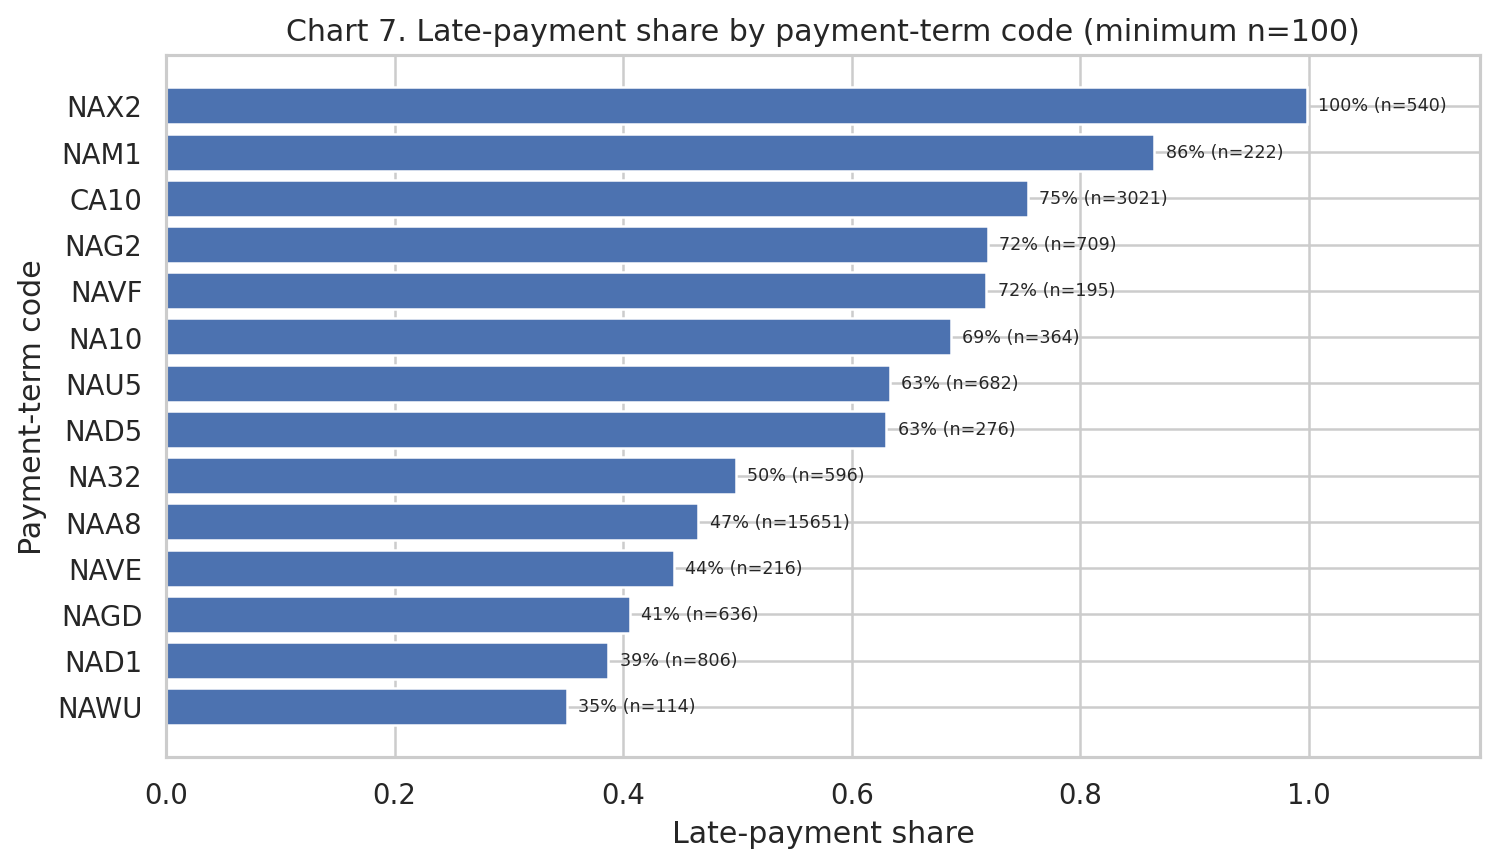

In [11]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart07_terms_late_rate.png')))

### Chart08 Monthly Volume

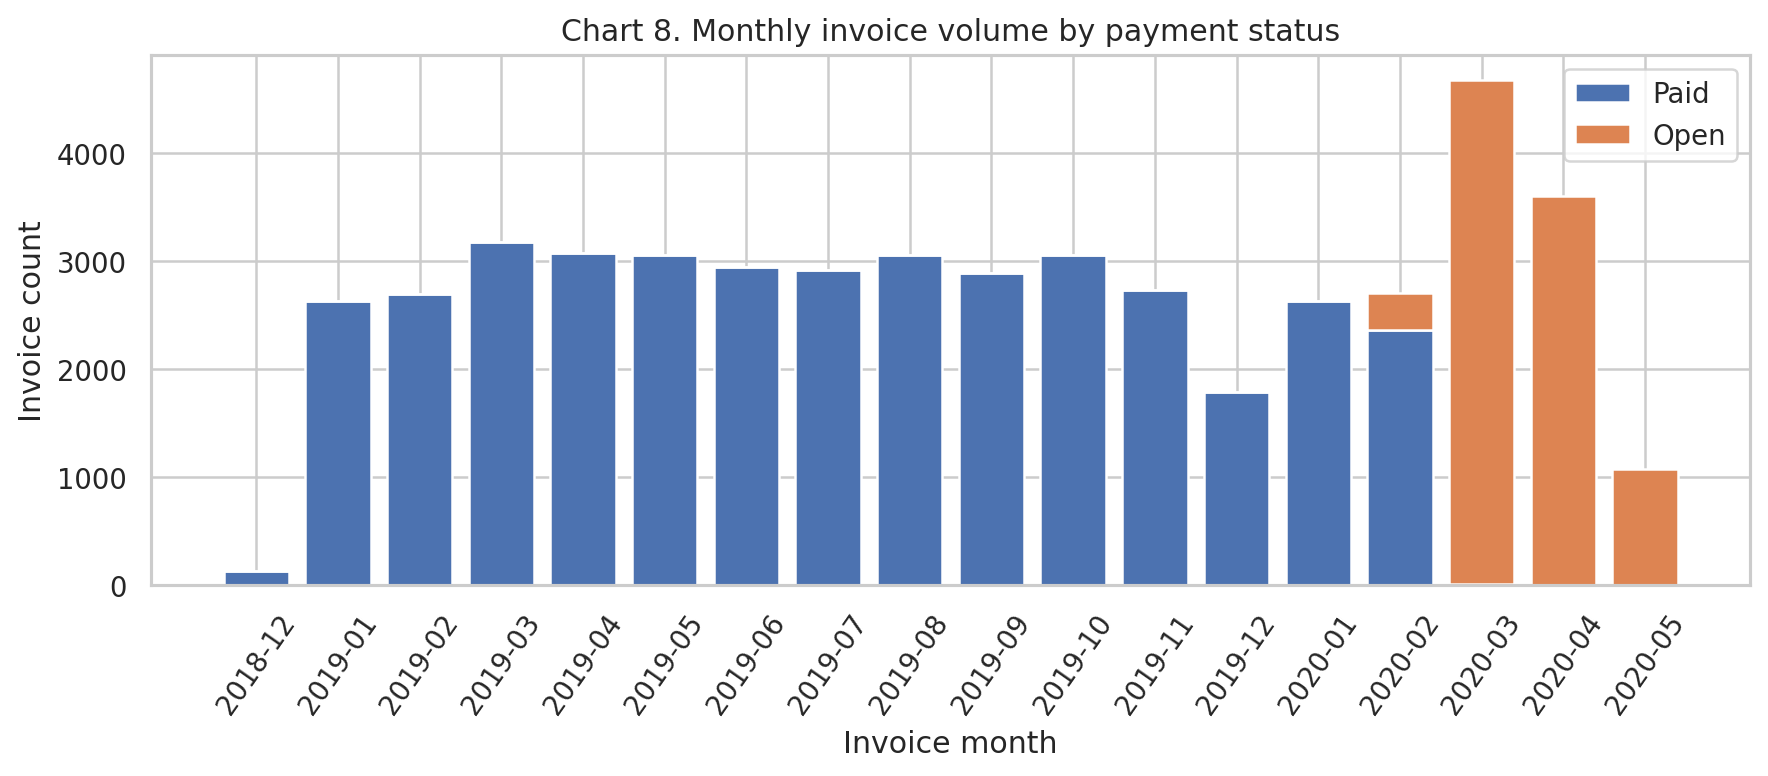

In [12]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart08_monthly_volume.png')))

### Chart09 Monthly Late Rate

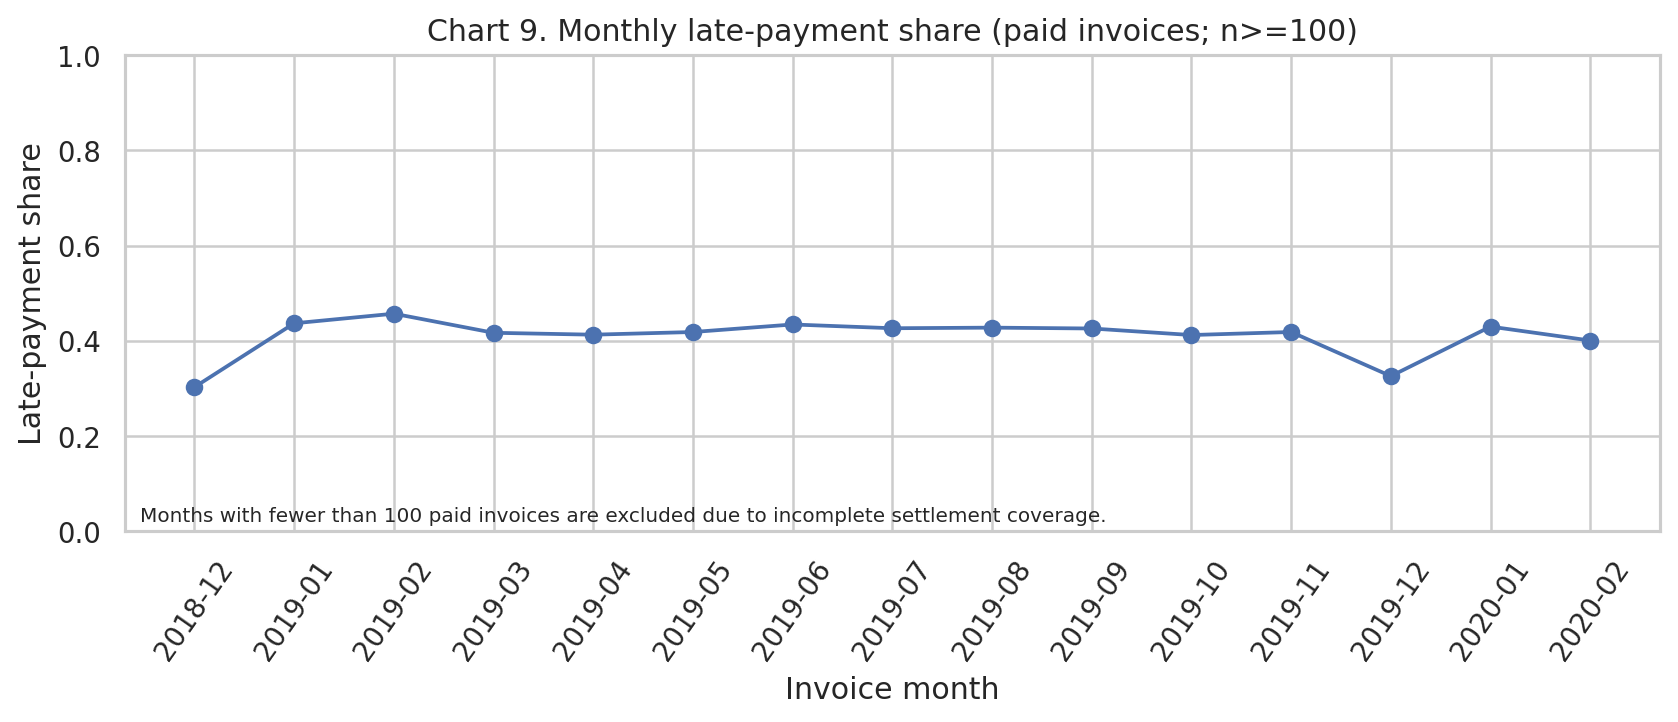

In [13]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart09_monthly_late_rate.png')))

### Chart10 Due Weekday

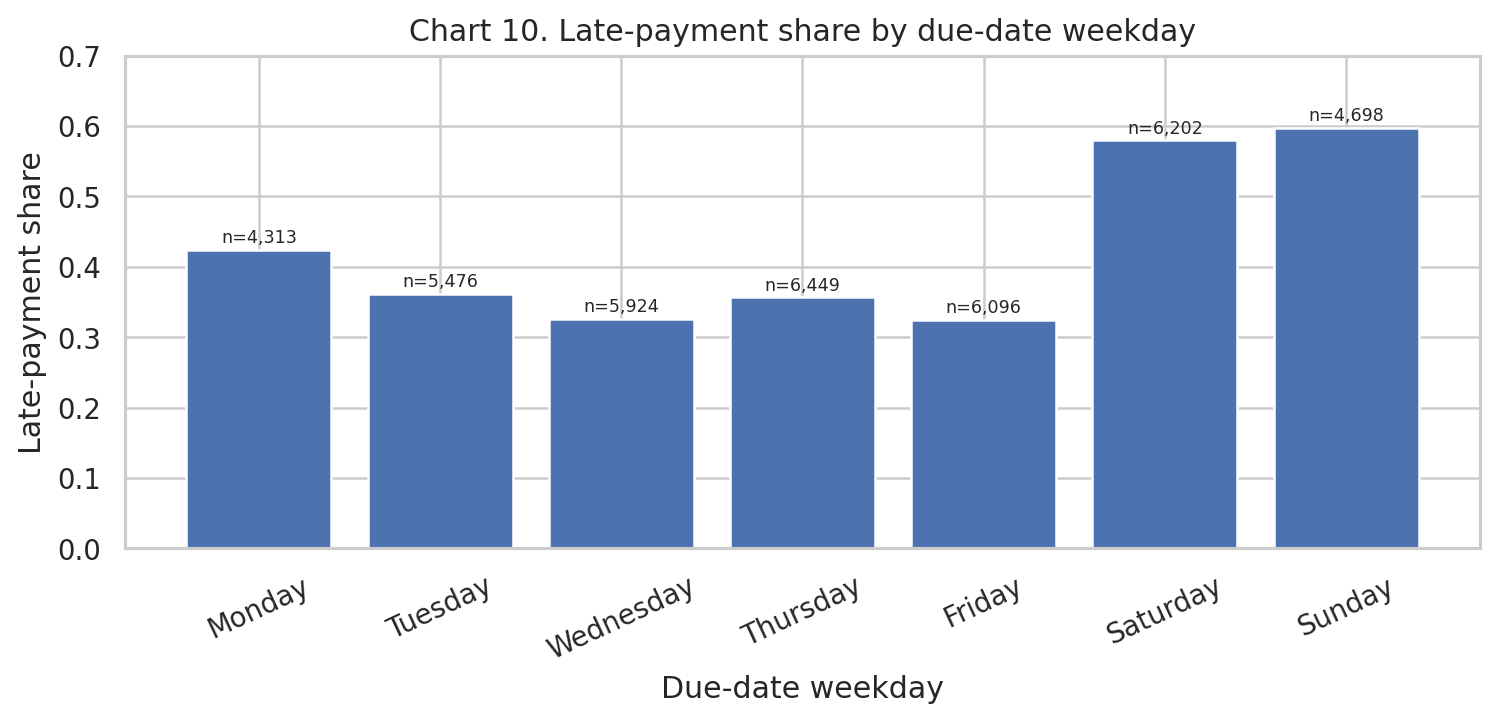

In [14]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart10_due_weekday.png')))

### Chart11 Customer Late Rate

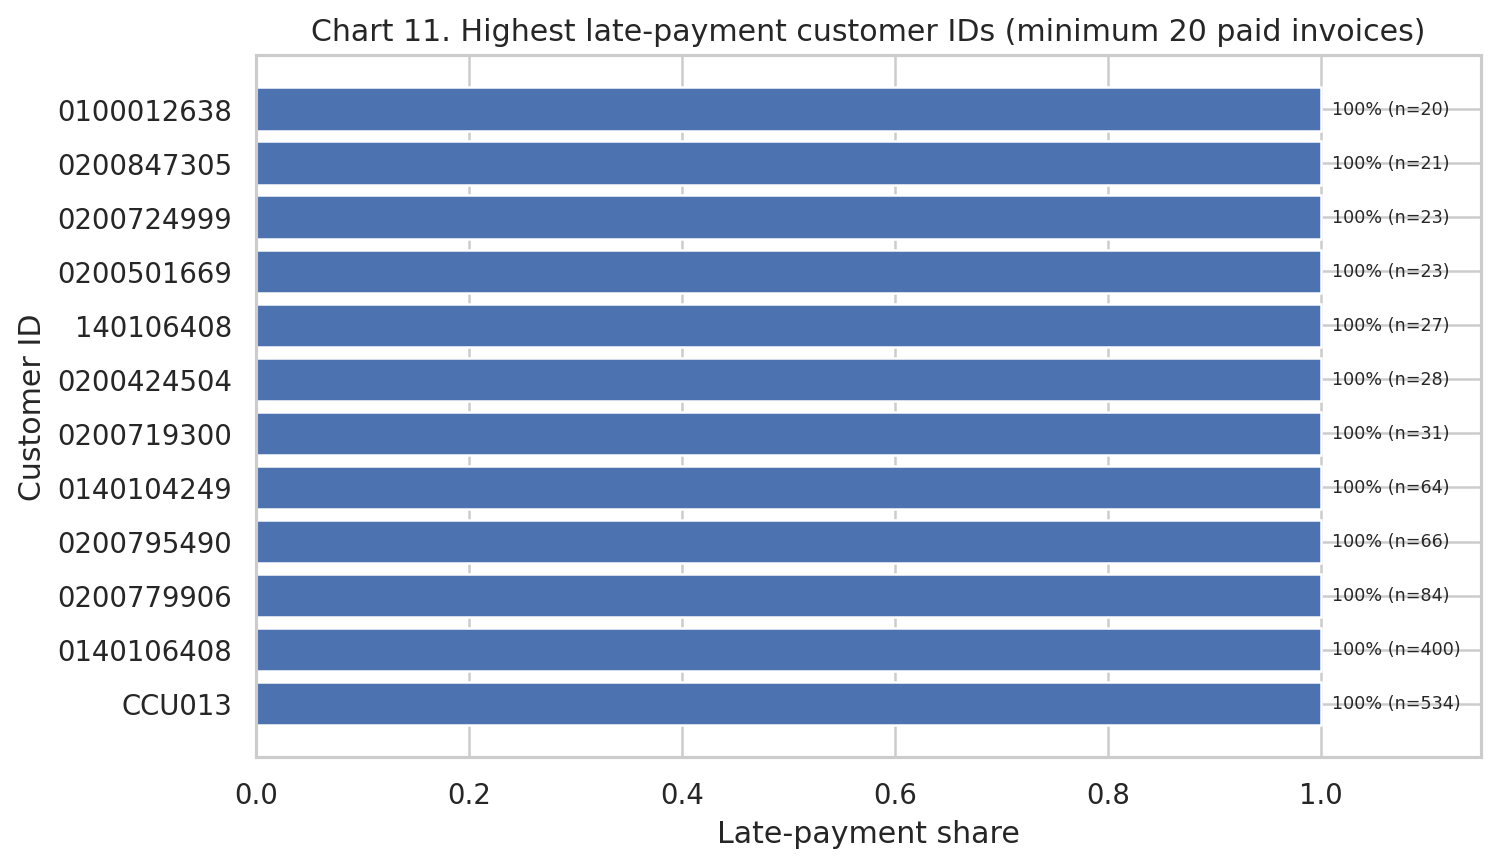

In [15]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart11_customer_late_rate.png')))

### Chart12 Customer Repeat

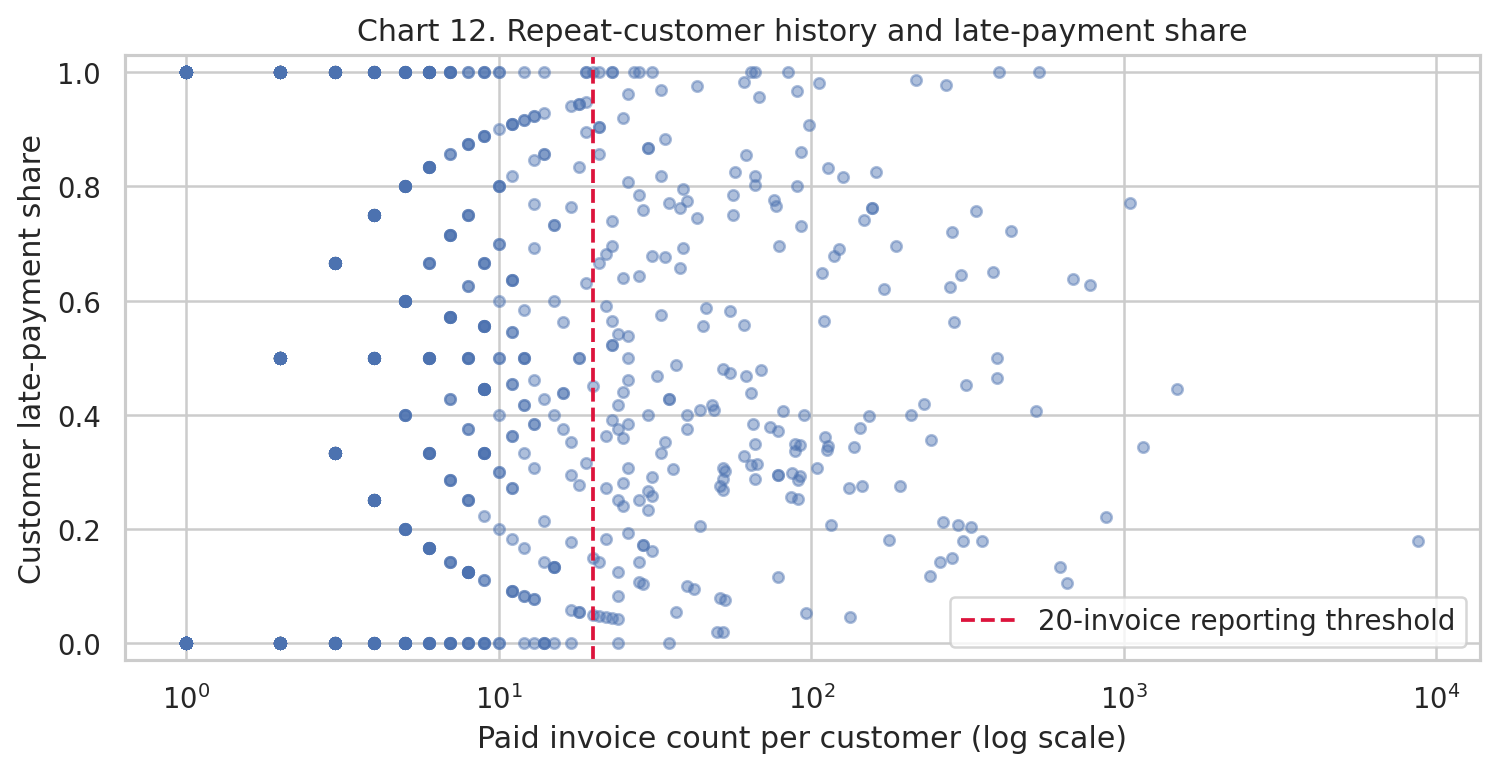

In [16]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart12_customer_repeat.png')))

### Chart13 Aging Count

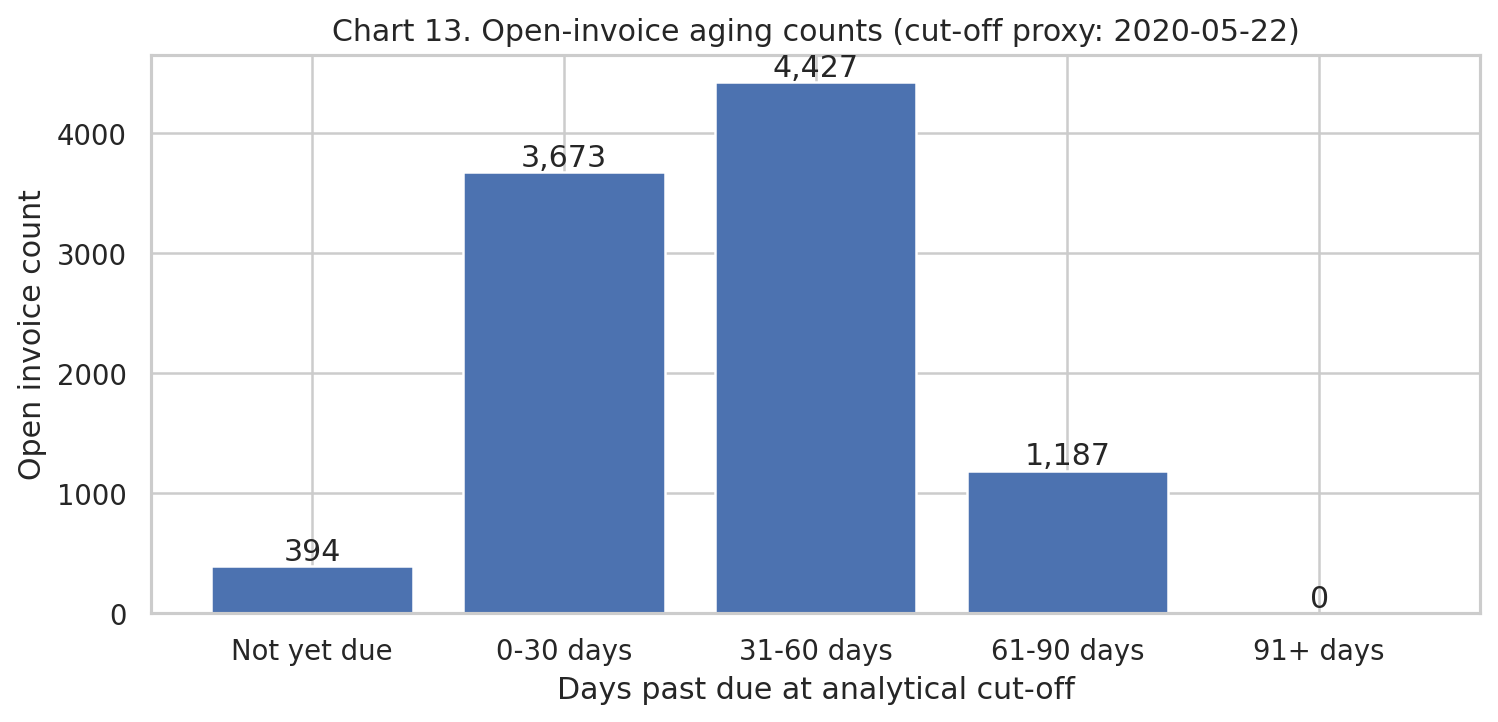

In [17]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart13_aging_count.png')))

### Chart14 Aging Amount Currency

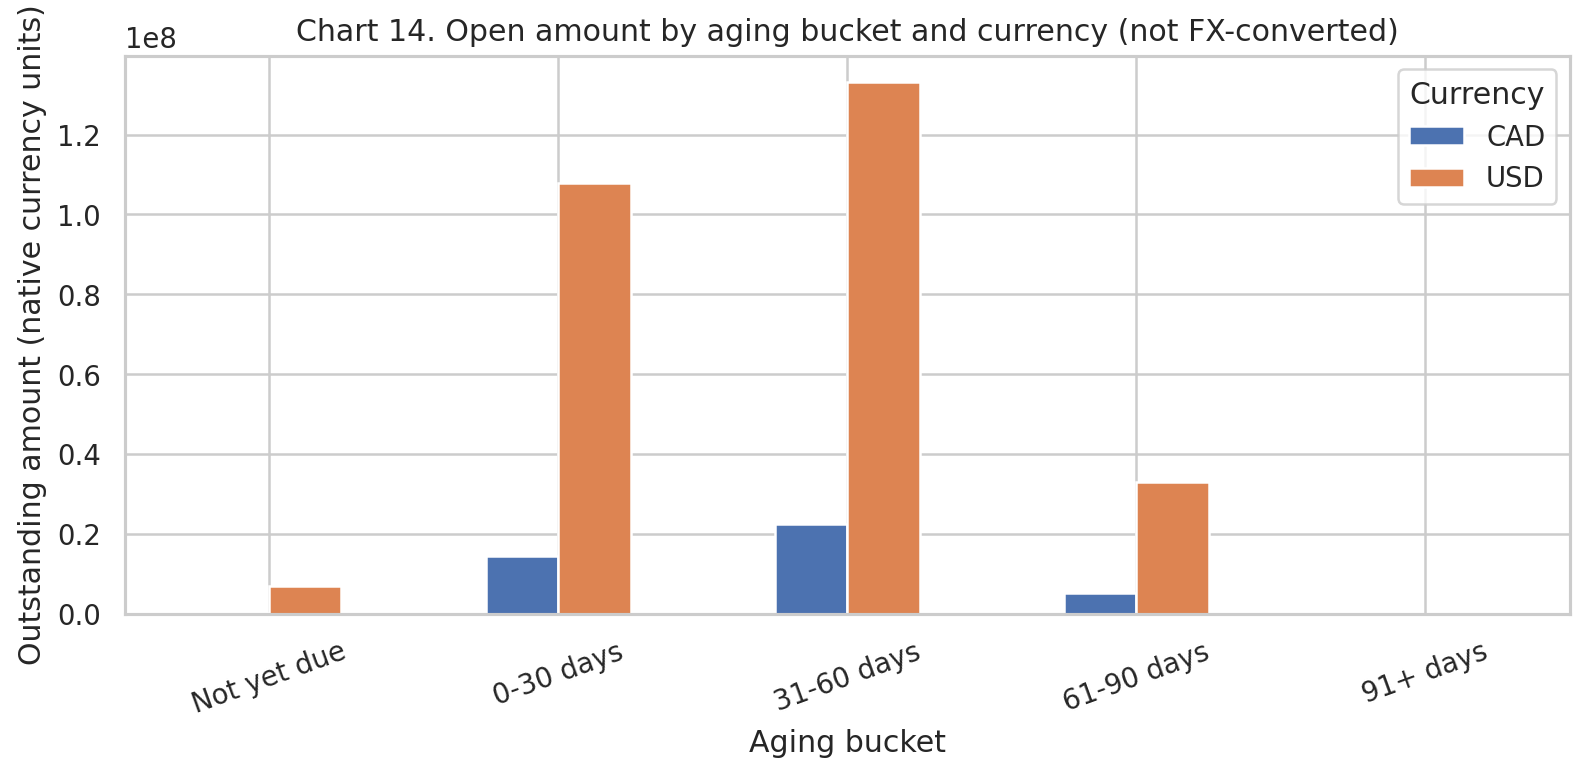

In [18]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart14_aging_amount_currency.png')))

### Chart15 Correlation Heatmap

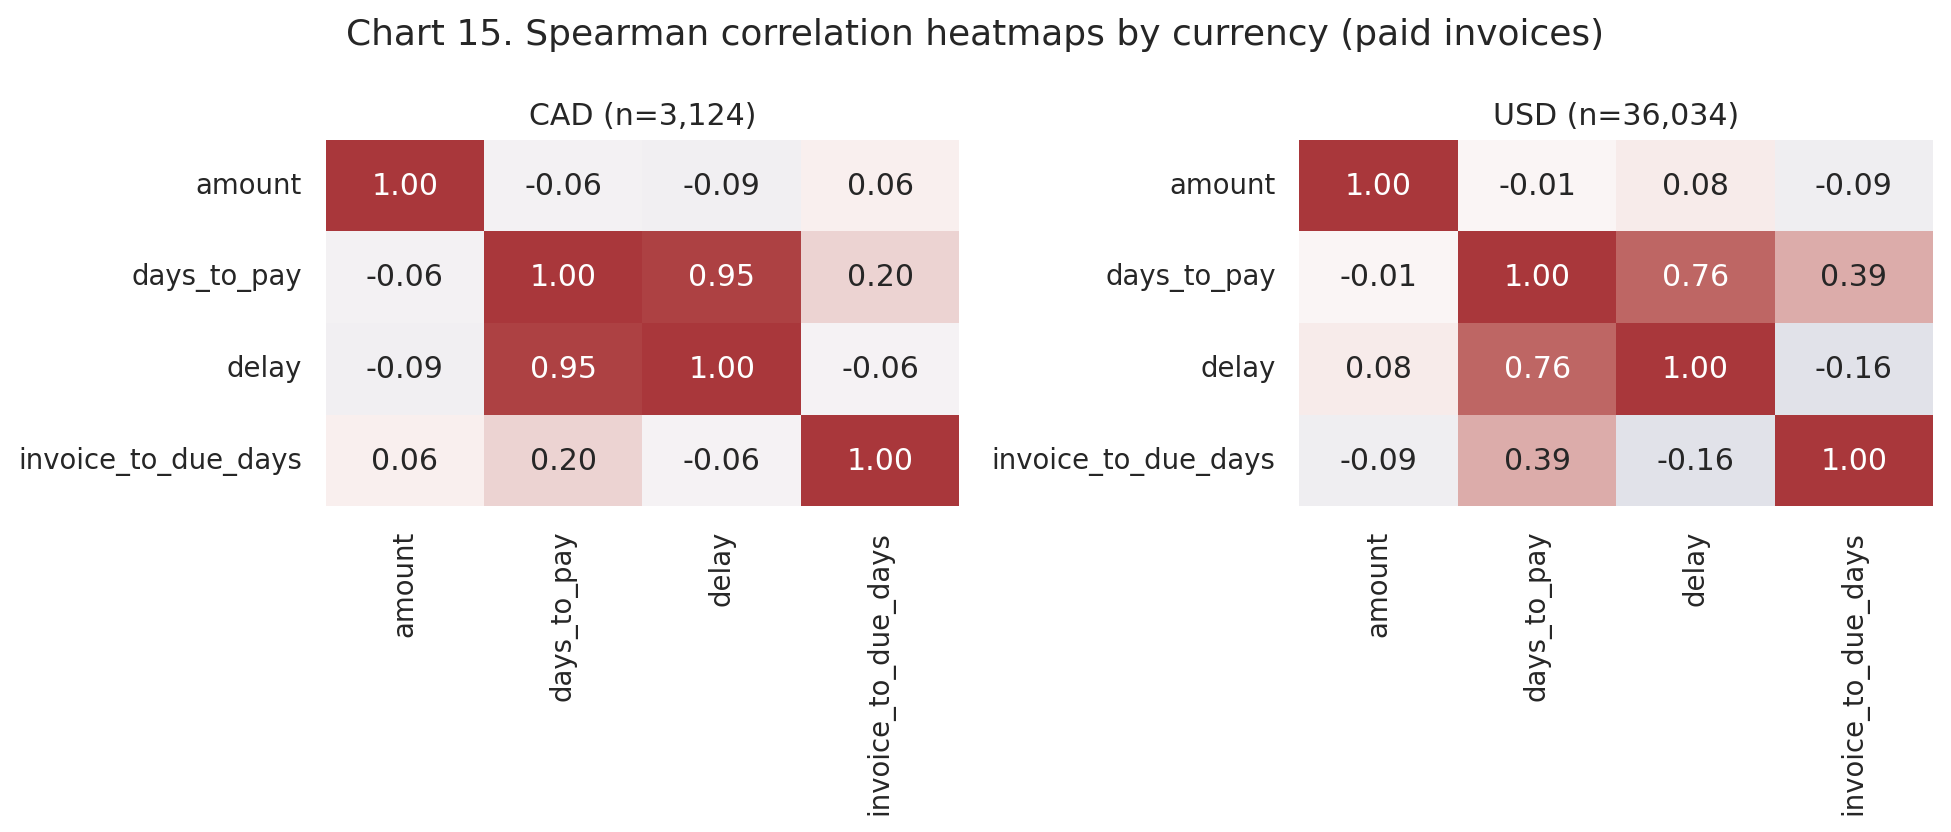

In [19]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart15_correlation_heatmap.png')))

### Chart16 Period End Effect

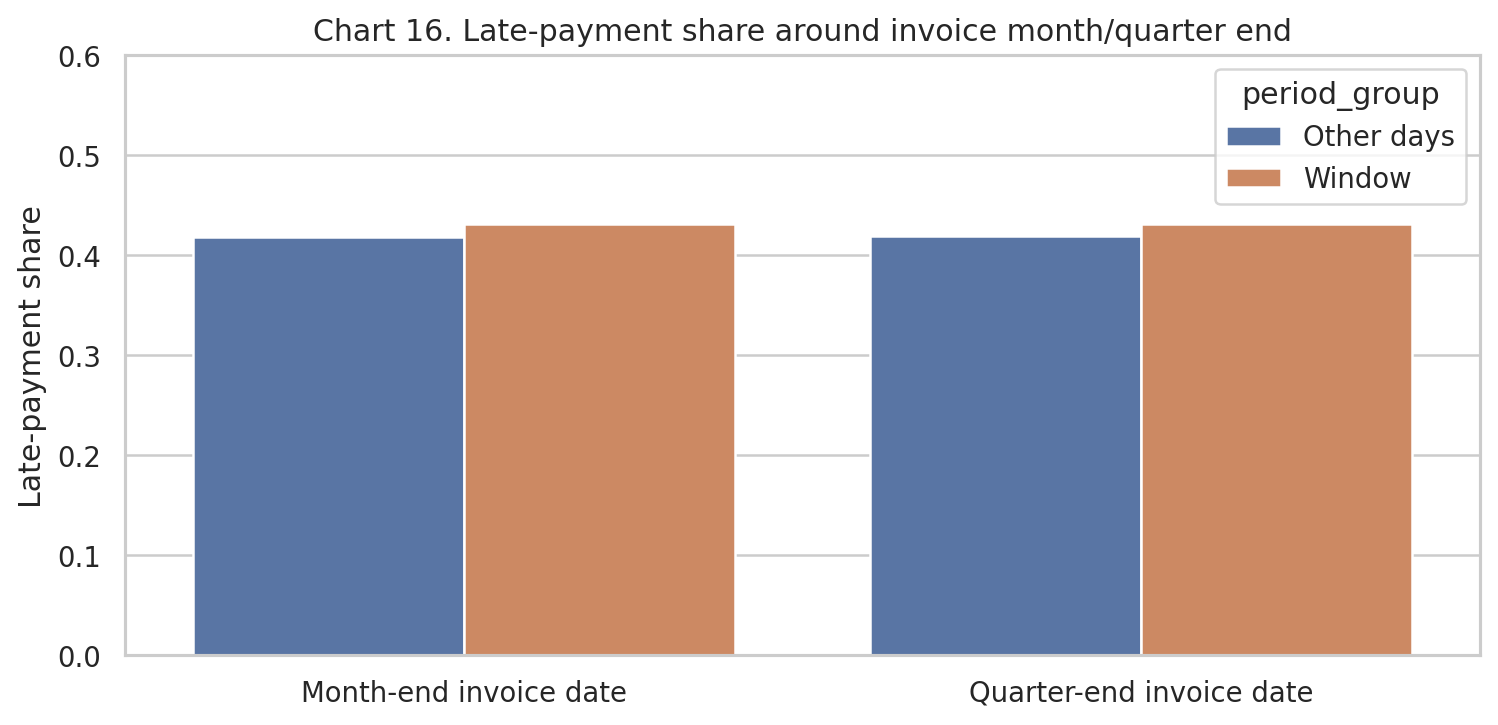

In [20]:
display(Image(filename=str(OUTPUT_PATH / 'charts' / 'chart16_period_end_effect.png')))

## 5. Insights and ML hypotheses

In [21]:
insight_table = pd.read_csv(OUTPUT_PATH / 'insights_and_hypotheses.csv')
display(insight_table[['id','theme','finding','business_interpretation','ml_hypothesis']])

,id,theme,finding,business_interpretation,ml_hypothesis
0,1,Payment outcomes,"Of 39,158 paid invoices, 16,418 (41.9%) were l...",A material share of settlements arrive after d...,A binary late-payment classifier using only in...
1,2,Payment terms,"Among terms with at least 100 paid invoices, N...",Observed repayment behaviour differs strongly ...,Payment-term code is a useful categorical pred...
2,3,Due weekday,Paid invoices due on Sunday and Saturday had l...,Calendar-day delay may be elevated when contra...,Due weekday and weekend/holiday indicators may...
3,4,Outstanding exposure,"There were 9,681 open invoices (19.8% of recor...",Unpaid exposure is material. Currency totals m...,A cash-collection prioritization model can ran...
4,5,Aging concentration,"The 31-60 days overdue bucket contained 4,427 ...",Collections operations should focus on invoice...,A multi-class aging-risk model or time-to-paym...
5,6,Repeat-customer risk,Among customer IDs with at least 20 paid invoi...,Historical payment behaviour varies by custome...,Use leakage-safe historical customer aggregate...
6,7,Amount and delay,Spearman correlation between amount and delay ...,Invoice size alone has a weak monotonic relati...,Amount may need nonlinear transforms and inter...
7,8,Time coverage and censoring,"Invoice volume peaked in 2020-03 (4,674 invoic...","Recent invoices have not all settled, so compl...",Use a time-based split and consider survival/t...
8,9,Month-end / quarter-end,Invoices created in the last 3 days of a month...,The differences are modest in this sample. Cal...,Add month-end and quarter-end flags as candida...
9,10,Amount distribution / outliers,"Invoice amount is strongly right-skewed; 2,460...",A small number of large invoices can materiall...,"Compare log1p(amount), robust scaling and tree..."


## 6. Data limitations and responsible interpretation

- The country column is entirely missing; country EDA is not possible from this dataset.
- CAD and USD invoice amounts are not added together or compared as if they were the same unit. No FX conversion input was provided.
- The file has no official snapshot timestamp. Aging uses 22 May 2020 as a stated proxy cut-off (latest observed invoice/payment date); the buckets change if the true reporting cut-off differs.
- Open invoices are right-censored: payment delay and days to pay are unknown until settlement. Never replace those missing outcomes with zero.
- Customer IDs are used to group history because customer names vary within IDs. Validate the mapping with the mentor.
- Payment terms remain source codes; their business definitions are not supplied.
- EDA findings are correlations/descriptive patterns, not causal proof. Model development should use a time-based split and features available at prediction time only.